Karol Alexis Alvarado Davila - A01751711

Inteligencia artificial avanzada para la ciencia de datos

TC3009C.601

Momento de Retroalimentacion: Modulo 5 Implementacion de un modelo de deep learning. (Portafolio Implementacion)

viernes 13 de noviembre de 2026

Introduccion

En la sangre hay varios tipos de globulos blancos y cada uno cumple una funcion distinta en el sistema inmune. El conteo diferencial, que es saber cuantos hay de cada tipo en una muestra, forma parte de la biometria hematica y ayuda a orientar el diagnostico de infecciones, alergias y enfermedades de la sangre. Cuando este conteo se hace a mano, una persona revisa el frotis en el microscopio y clasifica celula por celula, lo cual es lento y depende de su experiencia.

El problema que se busca resolver es clasificar de forma automatica la imagen de un globulo blanco en uno de cuatro tipos: eosinofilo, linfocito, monocito o neutrofilo. Es un problema de clasificacion de imagenes con 4 clases, y se resuelve con una red neuronal convolucional, porque lo que distingue a cada tipo es la forma del nucleo y la textura de la celula, que son patrones espaciales.

Datos

Paso 1. Fuente y carga de los datos

Se usa el dataset Blood Cell Images, publicado por Paul Mooney en Kaggle: https://www.kaggle.com/datasets/paultimothymooney/blood-cells

El dataset no se incluye en el repositorio por su peso. Para correr el notebook se descarga el zip de la liga anterior y la carpeta dataset2-master se coloca dentro de la carpeta data, en la raiz del repositorio. Las imagenes ya vienen separadas en carpetas por conjunto (TRAIN, TEST y TEST_SIMPLE) y por clase.

In [1]:
%matplotlib inline
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(0)
tf.random.set_seed(0)
plt.rcParams["figure.figsize"] = (8, 4)

In [2]:
# ruta de las imagenes y nombres de las clases
ruta = pathlib.Path("..") / "data" / "dataset2-master" / "images"
conjuntos = ["TRAIN", "TEST", "TEST_SIMPLE"]
clases = sorted(os.listdir(ruta / "TRAIN"))
print("Clases:", clases)

Clases: ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']


Paso 2. Imagenes por clase y por conjunto

            TRAIN  TEST  TEST_SIMPLE
EOSINOPHIL   2497   623           13
LYMPHOCYTE   2483   620            6
MONOCYTE     2478   620            4
NEUTROPHIL   2499   624           48
Total        9957  2487           71


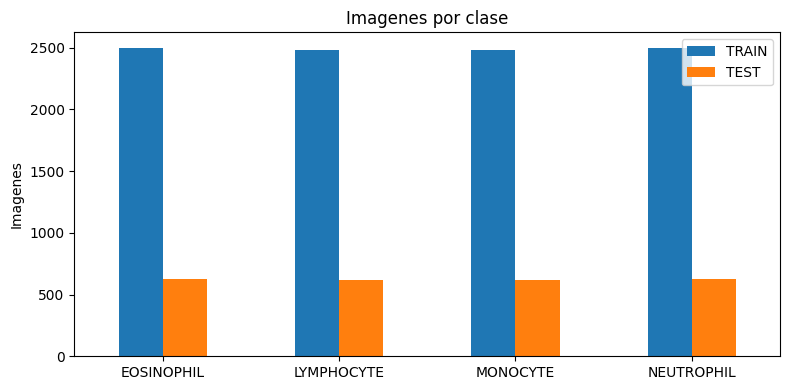

In [3]:
# conteo de imagenes por clase en cada conjunto
conteo = pd.DataFrame(index=clases)
for conjunto in conjuntos:
    conteo[conjunto] = [len(os.listdir(ruta / conjunto / clase)) for clase in clases]
conteo.loc["Total"] = conteo.sum()
print(conteo)

# grafica de barras de TRAIN y TEST
conteo.drop("Total")[["TRAIN", "TEST"]].plot.bar(rot=0)
plt.ylabel("Imagenes")
plt.title("Imagenes por clase")
plt.tight_layout()
plt.show()

Hay 9957 imagenes en TRAIN y 2487 en TEST. En ambos conjuntos las cuatro clases tienen casi la misma cantidad, alrededor de 2490 imagenes por clase en TRAIN y 620 en TEST, por lo que el dataset esta balanceado y el accuracy es una metrica adecuada. Como hay 4 clases balanceadas, un modelo que adivina al azar tendria un accuracy cercano a 25 por ciento, y ese es el punto de comparacion.

TEST_SIMPLE es distinto: tiene solo 71 imagenes y esta desbalanceado, con 48 neutrofilos y 4 monocitos.

Paso 3. Tamano y formato de las imagenes

In [4]:
# tamano de una muestra de 200 imagenes por clase
tamanos = {}
for conjunto in ["TRAIN", "TEST"]:
    for clase in clases:
        for archivo in os.listdir(ruta / conjunto / clase)[:200]:
            imagen = keras.utils.load_img(ruta / conjunto / clase / archivo)
            tamanos[imagen.size] = tamanos.get(imagen.size, 0) + 1
print("Tamanos (ancho, alto) y cantidad:", tamanos)

# forma y rango de valores de una imagen
arreglo = keras.utils.img_to_array(imagen)
print("Forma:", arreglo.shape, " minimo:", arreglo.min(), " maximo:", arreglo.max())

Tamanos (ancho, alto) y cantidad: {(320, 240): 1600}
Forma: (240, 320, 3)  minimo: 0.0  maximo: 255.0


Las 1600 imagenes revisadas miden 320 de ancho por 240 de alto y tienen 3 canales (RGB), con valores entre 0 y 255. Como todas tienen el mismo tamano no hace falta recortarlas, pero si conviene reducirlas y pasar los valores a un rango de 0 a 1 antes de entrar a la red.

Paso 4. Ejemplos de cada clase

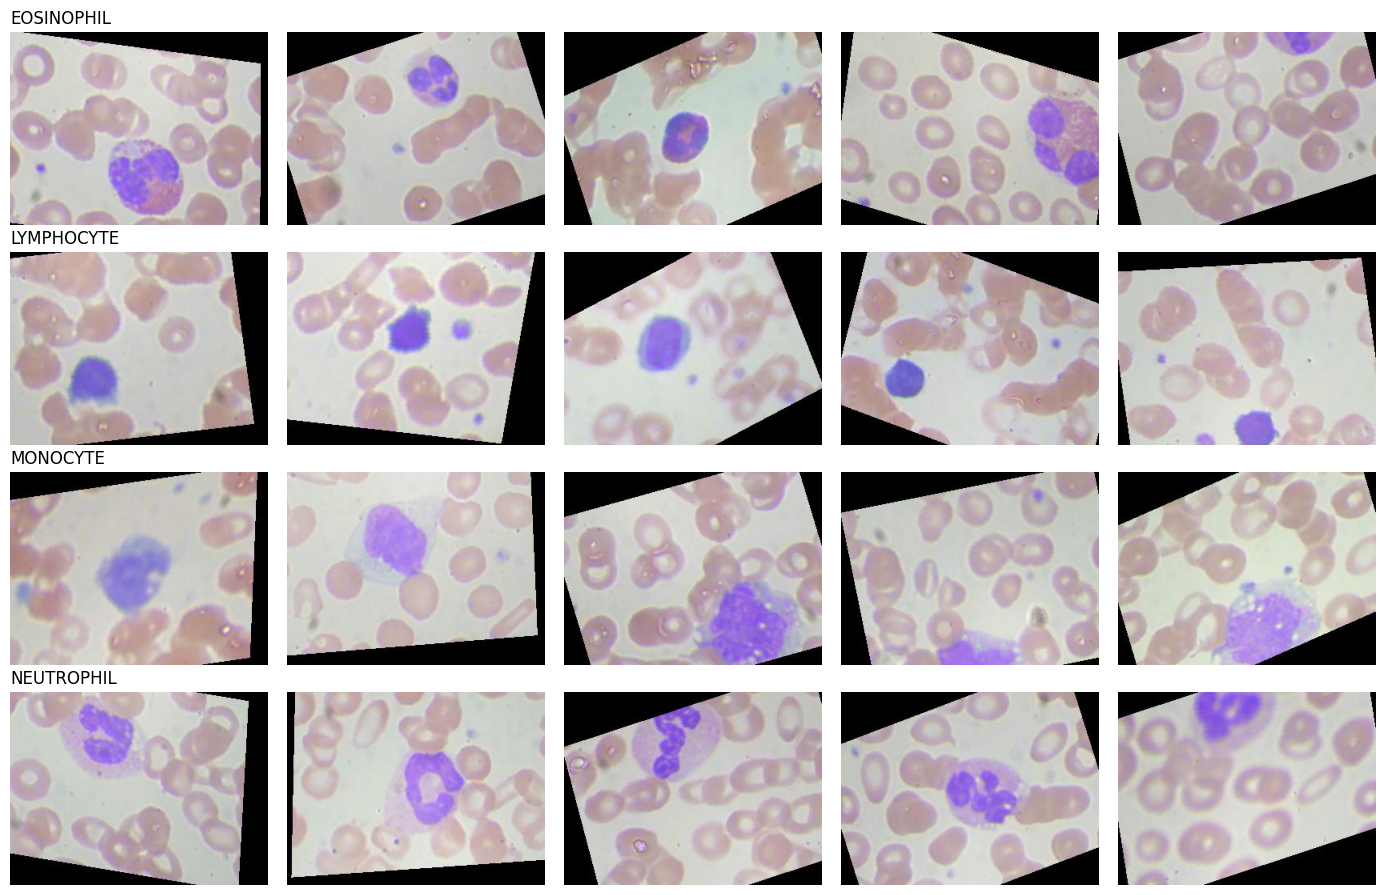

In [5]:
# cinco imagenes al azar de cada clase
fig, ejes = plt.subplots(len(clases), 5, figsize=(14, 9))
for i, clase in enumerate(clases):
    archivos = np.random.choice(os.listdir(ruta / "TRAIN" / clase), 5, replace=False)
    for j, archivo in enumerate(archivos):
        ejes[i, j].imshow(keras.utils.load_img(ruta / "TRAIN" / clase / archivo))
        ejes[i, j].axis("off")
    ejes[i, 0].set_title(clase, loc="left")
plt.tight_layout()
plt.show()

En cada imagen hay un globulo blanco, tenido de morado, rodeado de globulos rojos. Lo que cambia entre clases es sobre todo el nucleo: en el linfocito es redondo y ocupa casi toda la celula, en el monocito es grande y con forma de rinon, en el neutrofilo esta dividido en varios lobulos y en el eosinofilo suele tener dos lobulos. El eosinofilo y el neutrofilo son los mas parecidos entre si, asi que se espera que sean las clases que mas se confundan.

Tambien se observa que muchas imagenes estan rotadas o desplazadas y tienen esquinas negras. Esto indica que las imagenes ya pasaron por un proceso de aumento de datos.

Paso 5. Imagenes originales e imagenes aumentadas

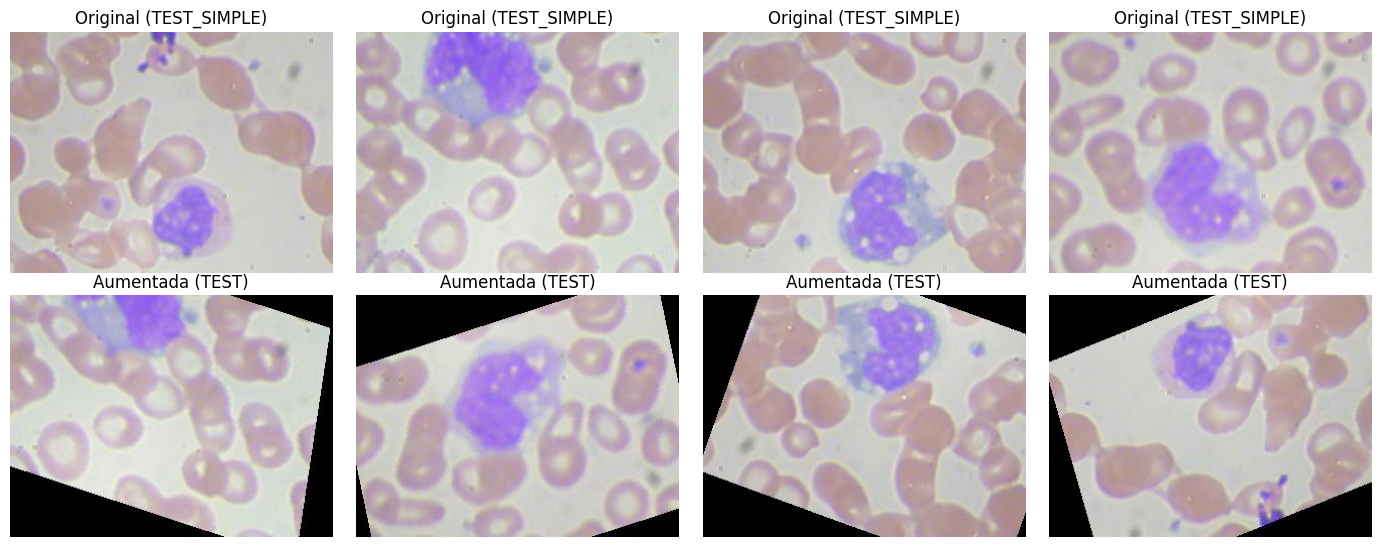

In [6]:
# los monocitos originales de TEST_SIMPLE y cuatro monocitos de TEST
originales = sorted(os.listdir(ruta / "TEST_SIMPLE" / "MONOCYTE"))
aumentadas = np.random.choice(os.listdir(ruta / "TEST" / "MONOCYTE"), 4, replace=False)
fig, ejes = plt.subplots(2, 4, figsize=(14, 5.5))
for j, archivo in enumerate(originales):
    ejes[0, j].imshow(keras.utils.load_img(ruta / "TEST_SIMPLE" / "MONOCYTE" / archivo))
    ejes[0, j].set_title("Original (TEST_SIMPLE)")
for j, archivo in enumerate(aumentadas):
    ejes[1, j].imshow(keras.utils.load_img(ruta / "TEST" / "MONOCYTE" / archivo))
    ejes[1, j].set_title("Aumentada (TEST)")
for eje in ejes.flat:
    eje.axis("off")
plt.tight_layout()
plt.show()

TEST_SIMPLE tiene 4 monocitos y TEST tiene 620. Al comparar las imagenes se observa que los monocitos de TEST son las mismas celulas de TEST_SIMPLE, pero rotadas, desplazadas o volteadas. Es decir, las imagenes de TEST no son fotos independientes, sino muchas versiones de pocas fotos originales. Lo mismo pasa en TRAIN.

Un detalle a senalar: esto afecta como se deben leer los resultados. El accuracy de prueba se calcula con pocas celulas distintas por clase, y en el caso de los monocitos con solo 4. Ademas, como las celulas de TEST son distintas a las de TRAIN, el conjunto de prueba mide que tan bien clasifica el modelo celulas que nunca vio, que es lo que interesa en la practica.

Paso 6. Separacion en entrenamiento, validacion y prueba

In [7]:
# tamano de entrada y tamano de lote
alto = 120
ancho = 160
lote = 32

# entrenamiento y validacion salen de TRAIN (80 y 20 por ciento)
datos_entrenamiento = keras.utils.image_dataset_from_directory(
    ruta / "TRAIN", validation_split=0.2, subset="training", seed=0,
    image_size=(alto, ancho), batch_size=lote)
datos_validacion = keras.utils.image_dataset_from_directory(
    ruta / "TRAIN", validation_split=0.2, subset="validation", seed=0,
    image_size=(alto, ancho), batch_size=lote)

# prueba: la carpeta TEST completa, sin revolver
datos_prueba = keras.utils.image_dataset_from_directory(
    ruta / "TEST", shuffle=False, image_size=(alto, ancho), batch_size=lote)

print("Clases:", datos_entrenamiento.class_names)

datos_entrenamiento = datos_entrenamiento.prefetch(tf.data.AUTOTUNE)
datos_validacion = datos_validacion.prefetch(tf.data.AUTOTUNE)
datos_prueba = datos_prueba.prefetch(tf.data.AUTOTUNE)

Found 9957 files belonging to 4 classes.


Using 7966 files for training.


Found 9957 files belonging to 4 classes.


Using 1991 files for validation.


Found 2487 files belonging to 4 classes.


Clases:

 ['EOSINOPHIL', 'LYMPHOCYTE', 'MONOCYTE', 'NEUTROPHIL']


Se respeta la separacion que trae el dataset: la carpeta TEST se usa completa como conjunto de prueba (2487 imagenes) y no se toca durante el entrenamiento. La carpeta TRAIN se divide en 80 por ciento para entrenamiento (7966 imagenes) y 20 por ciento para validacion (1991 imagenes). TEST_SIMPLE no se usa como conjunto de prueba porque sus celulas son las mismas de TEST.

Como preprocesamiento, las imagenes se reducen a la mitad, de 240x320 a 120x160, para que el entrenamiento sea mas rapido. Se conserva la proporcion original, asi que las celulas no se deforman. El paso de 0-255 a 0-1 se hace dentro del modelo con una capa Rescaling.

Un detalle a senalar: la validacion se saca al azar de TRAIN, y por lo visto en el Paso 5, TRAIN tiene varias versiones aumentadas de la misma celula. Entonces es muy probable que una celula tenga algunas versiones en entrenamiento y otras en validacion. Por eso el accuracy de validacion puede salir mas alto de lo que el modelo lograria con celulas nuevas, y el conjunto de prueba es la medida mas confiable de generalizacion.

Desarrollo del modelo

Paso 7. Arquitectura

Se construye una red convolucional sencilla como modelo base, sin tecnicas de regularizacion, para tener un punto de partida y poder medir despues el efecto de cada cambio. La red tiene cuatro bloques de convolucion con max pooling. Las capas convolucionales usan filtros de 3x3 con activacion relu, y el numero de filtros crece de 32 a 128 conforme la imagen se hace mas pequena: las primeras capas detectan bordes y colores, y las ultimas combinan esos patrones en formas mas complejas, como los lobulos del nucleo. Cada max pooling reduce el alto y el ancho a la mitad.

Al final, la capa Flatten convierte los mapas de caracteristicas en un vector, que pasa por una capa densa de 128 neuronas y por la capa de salida de 4 neuronas con activacion softmax, una por clase.

In [8]:
# modelo base: 4 bloques conv + pooling y un clasificador denso
modelo_base = keras.Sequential([
    keras.Input(shape=(alto, ancho, 3)),
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(4, activation="softmax"),
])
modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)                │ (None, 120, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 118, 158, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 59, 79, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 57, 77, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 28, 38, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 26, 36, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5120)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         655,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 896,836 (3.42 MB)

 Trainable params: 896,836 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

El modelo tiene 896,836 parametros entrenables. La imagen entra de 120x160 y, despues de los cuatro bloques, queda en mapas de 5x8 con 128 filtros, que al aplanarse dan un vector de 5120 valores. La mayor parte de los parametros esta en la primera capa densa, con 655,488, que es cerca del 73 por ciento del total. Las cuatro capas convolucionales juntas suman 240,832.

Paso 8. Entrenamiento

In [9]:
# compilacion y entrenamiento del modelo base
epocas = 20
modelo_base.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
historial_base = modelo_base.fit(datos_entrenamiento,
                                 validation_data=datos_validacion,
                                 epochs=epocas, verbose=2)

Epoch 1/20


249/249 - 33s - 133ms/step - accuracy: 0.2639 - loss: 1.3852 - val_accuracy: 0.3325 - val_loss: 1.3574


Epoch 2/20


249/249 - 29s - 117ms/step - accuracy: 0.4182 - loss: 1.2478 - val_accuracy: 0.5595 - val_loss: 1.0439


Epoch 3/20


249/249 - 29s - 117ms/step - accuracy: 0.5885 - loss: 0.9380 - val_accuracy: 0.6429 - val_loss: 0.8518


... (30 outputs left out)

Epoch 19/20


249/249 - 29s - 116ms/step - accuracy: 0.9413 - loss: 0.1629 - val_accuracy: 0.8574 - val_loss: 0.3452


Epoch 20/20


249/249 - 29s - 115ms/step - accuracy: 0.9500 - loss: 0.1500 - val_accuracy: 0.8699 - val_loss: 0.3069


Se usa el optimizador Adam con una tasa de aprendizaje de 0.0001. La funcion de perdida es sparse categorical crossentropy porque es un problema de varias clases y las etiquetas vienen como enteros de 0 a 3, no en one-hot. La metrica es accuracy, que es adecuada porque las clases estan balanceadas.

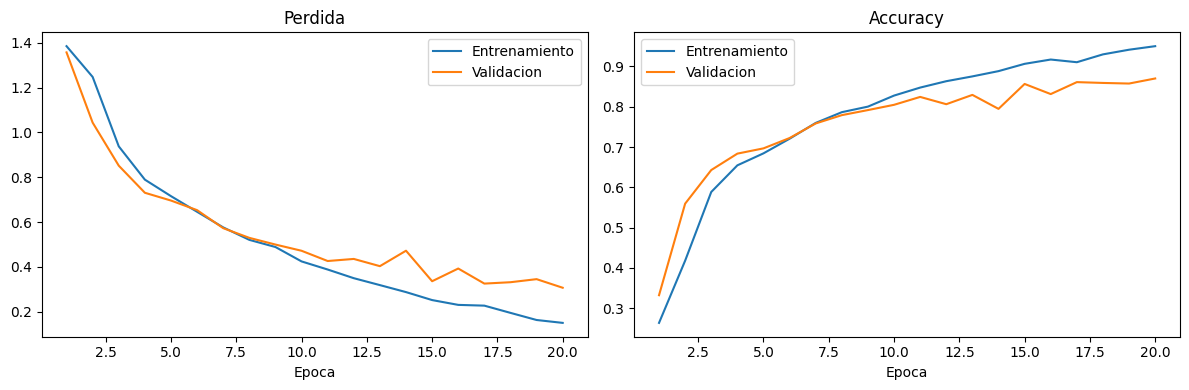

Ultima epoca: accuracy entrenamiento = 0.95  accuracy validacion = 0.8699
Menor perdida de validacion en la epoca 20 : 0.3069


In [10]:
# curvas de perdida y accuracy
historia = historial_base.history
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(range(1, epocas + 1), historia["loss"], label="Entrenamiento")
ejes[0].plot(range(1, epocas + 1), historia["val_loss"], label="Validacion")
ejes[0].set_title("Perdida")
ejes[0].set_xlabel("Epoca")
ejes[0].legend()
ejes[1].plot(range(1, epocas + 1), historia["accuracy"], label="Entrenamiento")
ejes[1].plot(range(1, epocas + 1), historia["val_accuracy"], label="Validacion")
ejes[1].set_title("Accuracy")
ejes[1].set_xlabel("Epoca")
ejes[1].legend()
plt.tight_layout()
plt.show()

# resultados de la ultima epoca y mejor epoca en validacion
mejor = int(np.argmin(historia["val_loss"])) + 1
print("Ultima epoca: accuracy entrenamiento =", round(historia["accuracy"][-1], 4),
      " accuracy validacion =", round(historia["val_accuracy"][-1], 4))
print("Menor perdida de validacion en la epoca", mejor, ":", round(min(historia["val_loss"]), 4))

En la primera epoca el modelo casi no aprende: el accuracy es de 26.39 por ciento, muy cerca del 25 por ciento que daria adivinar al azar entre 4 clases, y la perdida es de 1.3852. A partir de la segunda epoca la perdida empieza a bajar de forma constante.

Al final de las 20 epocas el accuracy de entrenamiento es de 95.00 por ciento y el de validacion de 86.99 por ciento. La menor perdida de validacion (0.3069) se da en la ultima epoca, lo que indica que el modelo todavia seguia mejorando cuando termino el entrenamiento y que 20 epocas no fueron suficientes para que convergiera.

Hasta la epoca 9 las dos curvas van practicamente juntas. Despues se empiezan a separar: el entrenamiento sigue subiendo mas rapido que la validacion y la diferencia final es de 8.0 puntos. Esto indica sobreajuste, aunque todavia no es grave porque la perdida de validacion no ha empezado a subir. En la epoca 14 la validacion tiene una caida puntual (accuracy de 79.46 por ciento) y se recupera en la epoca siguiente.

Un detalle a senalar: por lo explicado en el Paso 6, el accuracy de validacion puede estar inflado porque comparte celulas con el entrenamiento. La evaluacion con el conjunto de prueba es la que dice que tanto generaliza el modelo.

In [11]:
# se guarda el modelo base (arquitectura y pesos)
os.makedirs(pathlib.Path("..") / "modelos", exist_ok=True)
modelo_base.save(pathlib.Path("..") / "modelos" / "modelo_base.keras")
print("Modelo guardado en modelos/modelo_base.keras")

Modelo guardado en modelos/modelo_base.keras


Paso 9. Evaluacion con entrenamiento, validacion y prueba

In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# perdida y accuracy del modelo base en los tres conjuntos
evaluacion_base = pd.DataFrame(columns=["perdida", "accuracy"])
evaluacion_base.loc["entrenamiento"] = modelo_base.evaluate(datos_entrenamiento, verbose=0)
evaluacion_base.loc["validacion"] = modelo_base.evaluate(datos_validacion, verbose=0)
evaluacion_base.loc["prueba"] = modelo_base.evaluate(datos_prueba, verbose=0)
print(evaluacion_base.round(4))

               perdida  accuracy
entrenamiento   0.1442    0.9484
validacion      0.3069    0.8699
prueba          0.6760    0.7282


El accuracy es de 94.84 por ciento en entrenamiento, 86.99 por ciento en validacion y 72.82 por ciento en prueba.

Los tres valores estan muy por encima del 25 por ciento que daria adivinar al azar, asi que el modelo si aprendio a distinguir las clases. Como el accuracy de entrenamiento es alto, el modelo no tiene un problema de sesgo: tiene capacidad suficiente para ajustarse a los datos.

El problema esta en la diferencia entre conjuntos. De entrenamiento a prueba se pierden 22.0 puntos de accuracy y la perdida pasa de 0.1442 a 0.6760. Esto indica sobreajuste (varianza alta): el modelo aprendio detalles de las imagenes de entrenamiento que no le sirven con imagenes nuevas.

Tambien se observa que la validacion queda 14.2 puntos arriba de la prueba. Como la validacion comparte celulas con el entrenamiento y la prueba no, este resultado confirma lo que se anticipo en el Paso 6: la validacion sobreestima el desempeno real, y el numero que se debe tomar como referencia es el de prueba.

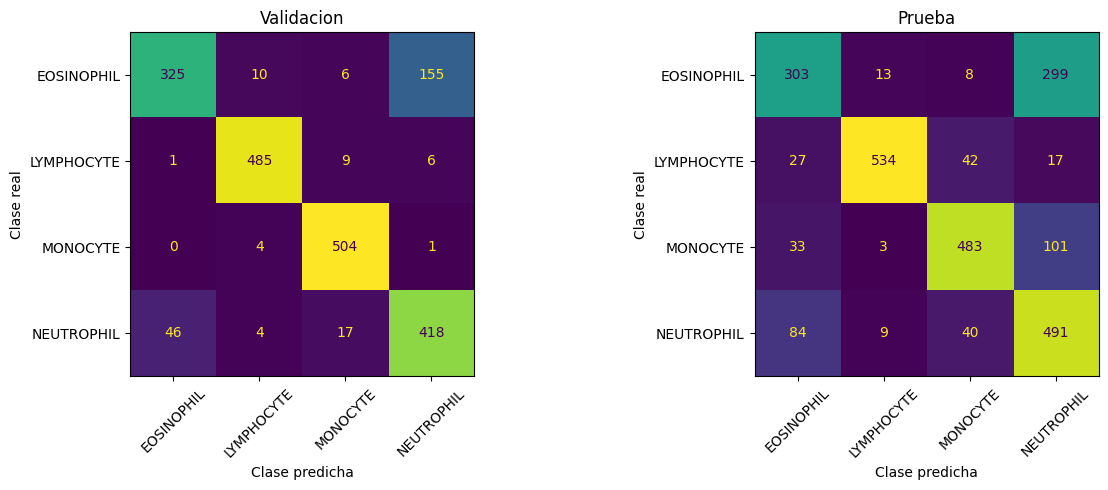

In [13]:
# etiquetas reales y predicciones de un conjunto, lote por lote
def predecir(modelo, datos):
    reales = []
    predichas = []
    for imagenes, etiquetas in datos:
        reales.append(etiquetas.numpy())
        predichas.append(np.argmax(modelo.predict_on_batch(imagenes), axis=1))
    return np.concatenate(reales), np.concatenate(predichas)

reales_val, pred_val = predecir(modelo_base, datos_validacion)
reales_prueba, pred_prueba = predecir(modelo_base, datos_prueba)

# matrices de confusion (filas: clase real, columnas: clase predicha)
matriz_val = confusion_matrix(reales_val, pred_val)
matriz_prueba = confusion_matrix(reales_prueba, pred_prueba)
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(matriz_val, display_labels=clases).plot(ax=ejes[0], colorbar=False, xticks_rotation=45)
ConfusionMatrixDisplay(matriz_prueba, display_labels=clases).plot(ax=ejes[1], colorbar=False, xticks_rotation=45)
ejes[0].set_title("Validacion")
ejes[1].set_title("Prueba")
for eje in ejes:
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

In [14]:
# accuracy por clase: aciertos de la diagonal entre el total de cada fila
por_clase = pd.DataFrame(index=clases)
por_clase["validacion"] = np.diag(matriz_val) / matriz_val.sum(axis=1)
por_clase["prueba"] = np.diag(matriz_prueba) / matriz_prueba.sum(axis=1)
por_clase["diferencia"] = por_clase["validacion"] - por_clase["prueba"]
print(por_clase.round(4))

# comprobacion a mano del accuracy de prueba
print("Accuracy de prueba a mano:", round(np.diag(matriz_prueba).sum() / matriz_prueba.sum(), 4))

            validacion  prueba  diferencia
EOSINOPHIL      0.6552  0.4864      0.1689
LYMPHOCYTE      0.9681  0.8613      0.1068
MONOCYTE        0.9902  0.7790      0.2111
NEUTROPHIL      0.8619  0.7869      0.0750
Accuracy de prueba a mano: 0.7282


En la prueba el modelo se equivoca en 676 de las 2487 imagenes. El error mas grande es entre eosinofilo y neutrofilo: 299 eosinofilos se clasifican como neutrofilo y 84 neutrofilos como eosinofilo. Juntas, estas dos confusiones suman 383 errores, que es el 56.7 por ciento de todos los errores. En validacion pasa lo mismo, con 155 y 46 casos. Esto coincide con lo que se vio en los ejemplos del Paso 4, donde estas dos clases eran las mas parecidas a simple vista. El eosinofilo es la clase con peor resultado: en prueba se reconoce el 48.64 por ciento, menos de la mitad.

El linfocito es la clase mas facil, con 86.13 por ciento en prueba. Su nucleo redondo que llena casi toda la celula lo distingue de las demas.

El monocito es la clase que mas cae entre conjuntos: pasa de 99.02 por ciento en validacion a 77.90 por ciento en prueba, una diferencia de 21.1 puntos. En validacion solo tiene 5 errores y en prueba tiene 137, la mayoria hacia neutrofilo (101). Un detalle a senalar: los 620 monocitos de prueba salen de solo 4 celulas originales, asi que cada celula aporta cerca de 155 imagenes. Si el modelo no reconoce bien una de esas celulas, falla en todas sus versiones a la vez, y eso es consistente con una caida de este tamano.

En resumen, el modelo base aprende pero sobreajusta, y sus errores se concentran en el par eosinofilo-neutrofilo. Estos dos puntos son los que se buscan mejorar en el ajuste del modelo.

Ajuste del modelo

Paso 10. Cambios respecto al modelo base

El modelo base tiene sobreajuste: aprende bien las imagenes de entrenamiento pero pierde cerca de 22 puntos de accuracy con celulas nuevas. Por eso los cambios de esta iteracion son tecnicas de regularizacion, que buscan que el modelo memorice menos y generalice mas. La arquitectura convolucional se deja igual para poder atribuir la diferencia a estos cambios.

1. Aumento de datos. Se agregan al inicio del modelo capas que modifican cada imagen de forma aleatoria en cada epoca: volteo horizontal y vertical, rotacion y zoom. Una celula sigue siendo del mismo tipo aunque se vea volteada, girada o un poco mas cerca, asi que estas transformaciones no cambian la etiqueta. Con esto el modelo casi nunca ve dos veces la misma imagen exacta, lo que le dificulta memorizar.

2. Dropout. Se agrega una capa Dropout de 0.5 antes de la capa densa, que es donde esta la mayoria de los parametros. En cada paso de entrenamiento se apaga al azar la mitad de las entradas de esa capa, de modo que el modelo no puede depender de unas pocas caracteristicas.

3. Mas epocas con early stopping. El modelo base seguia mejorando en la epoca 20, y con regularizacion el aprendizaje es mas lento, asi que el maximo sube a 30 epocas. Se usa EarlyStopping para detener el entrenamiento si la perdida de validacion deja de mejorar durante 5 epocas, y ModelCheckpoint para guardar el modelo de la mejor epoca.

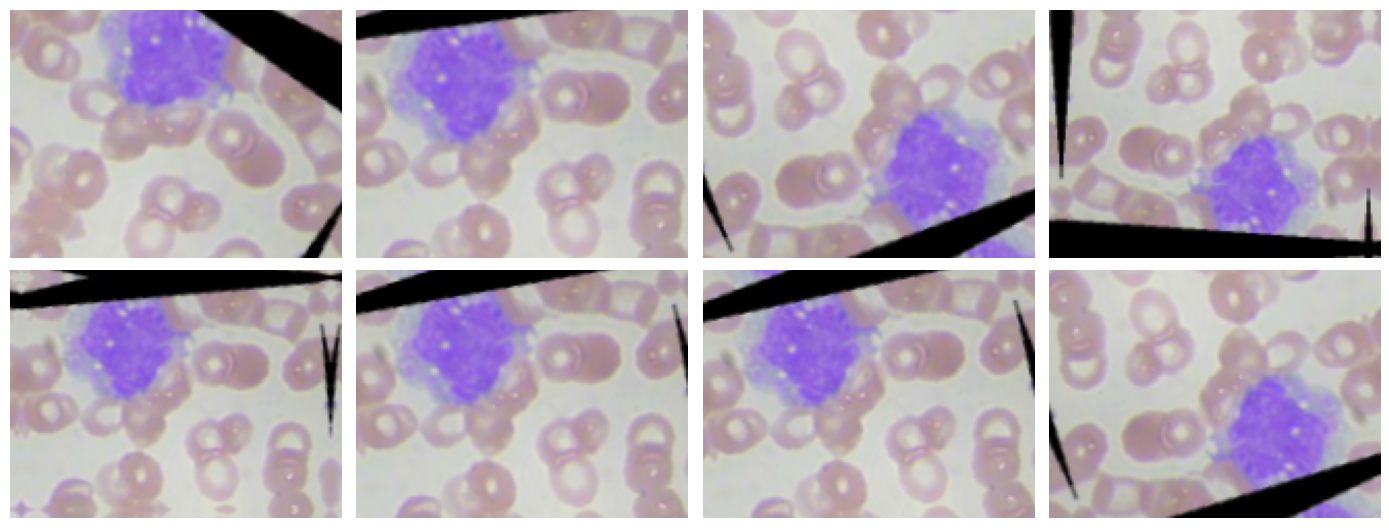

In [15]:
# capas de aumento de datos
aumento = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="aumento")

# una misma imagen de entrenamiento con ocho transformaciones distintas
for imagenes, etiquetas in datos_entrenamiento.take(1):
    fig, ejes = plt.subplots(2, 4, figsize=(14, 5.5))
    for eje in ejes.flat:
        aumentada = aumento(imagenes[:1], training=True)
        eje.imshow(aumentada[0].numpy().astype("uint8"))
        eje.axis("off")
    plt.tight_layout()
    plt.show()

Las ocho imagenes salen de la misma celula. Cambian la orientacion, el angulo y el acercamiento, pero el nucleo conserva su forma, que es lo que define la clase.

In [16]:
# modelo ajustado: mismos bloques conv del modelo base, con aumento de datos y dropout
modelo_ajustado = keras.Sequential([
    keras.Input(shape=(alto, ancho, 3)),
    aumento,
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(4, activation="softmax"),
])
modelo_ajustado.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ aumento (Sequential)                 │ (None, 120, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling_1 (Rescaling)              │ (None, 120, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 118, 158, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 59, 79, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 57, 77, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 28, 38, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 26, 36, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 13, 18, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 11, 16, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 5, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 5120)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 5120)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         655,488 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 896,836 (3.42 MB)

 Trainable params: 896,836 (3.42 MB)

 Non-trainable params: 0 (0.00 B)

El numero de parametros es el mismo del modelo base (896,836), porque las capas de aumento y de dropout no tienen pesos que entrenar. Ambas solo actuan durante el entrenamiento; al evaluar o predecir, la imagen pasa sin modificarse.

Paso 11. Entrenamiento del modelo ajustado

In [17]:
# se guarda la mejor epoca y se detiene si la validacion deja de mejorar
epocas_ajuste = 30
controles = [
    keras.callbacks.ModelCheckpoint(pathlib.Path("..") / "modelos" / "modelo_ajustado.keras",
                                    save_best_only=True, monitor="val_loss"),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
]
modelo_ajustado.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0001),
                        loss="sparse_categorical_crossentropy",
                        metrics=["accuracy"])
historial_ajustado = modelo_ajustado.fit(datos_entrenamiento,
                                         validation_data=datos_validacion,
                                         epochs=epocas_ajuste, callbacks=controles, verbose=2)

Epoch 1/30


249/249 - 35s - 140ms/step - accuracy: 0.2513 - loss: 1.3876 - val_accuracy: 0.2516 - val_loss: 1.3867


Epoch 2/30


249/249 - 33s - 132ms/step - accuracy: 0.2685 - loss: 1.3832 - val_accuracy: 0.3149 - val_loss: 1.3630


Epoch 3/30


249/249 - 33s - 131ms/step - accuracy: 0.4110 - loss: 1.2452 - val_accuracy: 0.5023 - val_loss: 1.0897


... (50 outputs left out)

Epoch 29/30


249/249 - 33s - 131ms/step - accuracy: 0.9263 - loss: 0.1869 - val_accuracy: 0.9272 - val_loss: 0.1842


Epoch 30/30


249/249 - 33s - 131ms/step - accuracy: 0.9197 - loss: 0.1914 - val_accuracy: 0.9523 - val_loss: 0.1439


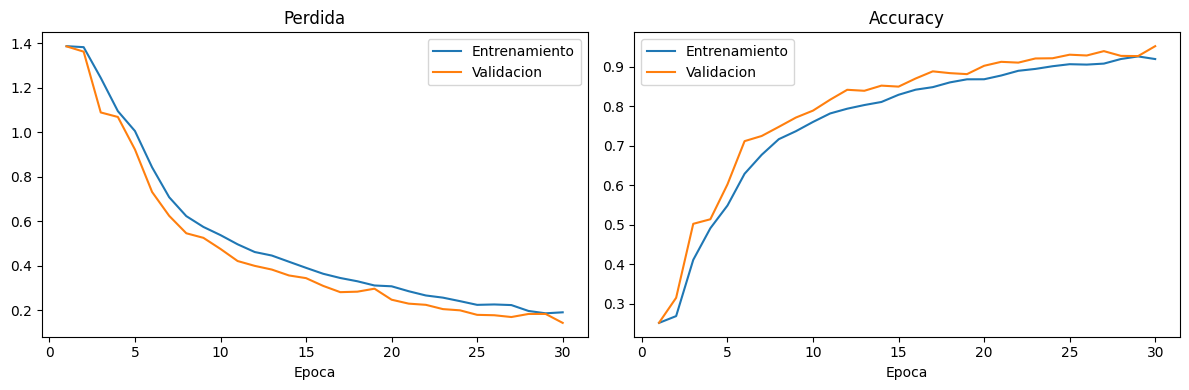

Epocas corridas: 30
Mejor epoca: 30  perdida de validacion = 0.1439  accuracy de validacion = 0.9523
Accuracy de entrenamiento en esa epoca = 0.9197


In [18]:
# curvas de perdida y accuracy del modelo ajustado
historia = historial_ajustado.history
corridas = len(historia["loss"])
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(range(1, corridas + 1), historia["loss"], label="Entrenamiento")
ejes[0].plot(range(1, corridas + 1), historia["val_loss"], label="Validacion")
ejes[0].set_title("Perdida")
ejes[0].set_xlabel("Epoca")
ejes[0].legend()
ejes[1].plot(range(1, corridas + 1), historia["accuracy"], label="Entrenamiento")
ejes[1].plot(range(1, corridas + 1), historia["val_accuracy"], label="Validacion")
ejes[1].set_title("Accuracy")
ejes[1].set_xlabel("Epoca")
ejes[1].legend()
plt.tight_layout()
plt.show()

mejor = int(np.argmin(historia["val_loss"])) + 1
print("Epocas corridas:", corridas)
print("Mejor epoca:", mejor, " perdida de validacion =", round(min(historia["val_loss"]), 4),
      " accuracy de validacion =", round(historia["val_accuracy"][mejor - 1], 4))
print("Accuracy de entrenamiento en esa epoca =", round(historia["accuracy"][mejor - 1], 4))

El entrenamiento corrio las 30 epocas, es decir, el early stopping no llego a activarse. La mejor epoca fue la ultima, con una perdida de validacion de 0.1439 y un accuracy de validacion de 95.23 por ciento. ModelCheckpoint guardo el modelo de esa epoca.

A diferencia del modelo base, las curvas de entrenamiento y validacion ya no se separan. En todas las epocas la validacion queda incluso por arriba del entrenamiento (95.23 contra 91.97 por ciento en la ultima). Esto se explica porque el aumento de datos y el dropout solo estan activos al entrenar: el accuracy de entrenamiento se mide con imagenes transformadas y con la mitad de las entradas de la capa densa apagadas, que es una tarea mas dificil que la de validacion.

El aprendizaje es mas lento que en el modelo base, que era lo esperado al regularizar: en las dos primeras epocas el accuracy se queda cerca de 25 por ciento y el modelo ajustado necesita 20 epocas para pasar de 90 por ciento en validacion. Un detalle a senalar: como la mejor epoca es la ultima, el modelo todavia no habia terminado de converger y es probable que pudiera mejorar con mas epocas.

Paso 12. Comparacion con el modelo base

In [19]:
# perdida y accuracy del modelo ajustado en los tres conjuntos
evaluacion_ajustado = pd.DataFrame(columns=["perdida", "accuracy"])
evaluacion_ajustado.loc["entrenamiento"] = modelo_ajustado.evaluate(datos_entrenamiento, verbose=0)
evaluacion_ajustado.loc["validacion"] = modelo_ajustado.evaluate(datos_validacion, verbose=0)
evaluacion_ajustado.loc["prueba"] = modelo_ajustado.evaluate(datos_prueba, verbose=0)

# tabla comparativa de accuracy
comparacion = pd.DataFrame({"base": evaluacion_base["accuracy"],
                            "ajustado": evaluacion_ajustado["accuracy"]})
comparacion["diferencia"] = comparacion["ajustado"] - comparacion["base"]
print(comparacion.round(4))
print("Perdida en prueba: base =", round(evaluacion_base.loc["prueba", "perdida"], 4),
      " ajustado =", round(evaluacion_ajustado.loc["prueba", "perdida"], 4))

                 base  ajustado  diferencia
entrenamiento  0.9484    0.9551      0.0067
validacion     0.8699    0.9523      0.0824
prueba         0.7282    0.8701      0.1419
Perdida en prueba: base = 0.676  ajustado = 0.251


El accuracy de prueba sube de 72.82 a 87.01 por ciento, una mejora de 14.2 puntos, y la perdida de prueba baja de 0.6760 a 0.2510. El accuracy de validacion tambien sube, de 86.99 a 95.23 por ciento.

El accuracy de entrenamiento practicamente no cambia (94.84 contra 95.51 por ciento). Entonces la mejora no viene de que el modelo se ajuste mas a los datos de entrenamiento, sino de que lo aprendido se traslada mejor a imagenes nuevas. La diferencia entre entrenamiento y prueba pasa de 22.0 a 8.5 puntos: el sobreajuste se redujo a menos de la mitad, aunque no desaparecio.

Un detalle a senalar: la comparacion entre modelos se hace con el conjunto de prueba porque, como se explico en el Paso 6, la validacion comparte celulas con el entrenamiento. Lo ideal seria elegir el modelo con un conjunto de validacion de celulas distintas y dejar la prueba solo para el reporte final.

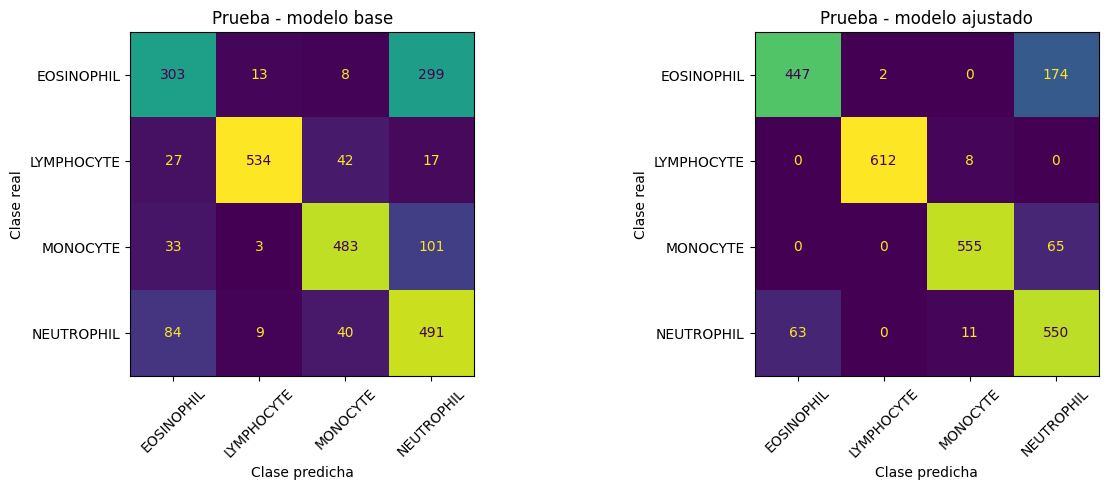

              base  ajustado  diferencia
EOSINOPHIL  0.4864    0.7175      0.2311
LYMPHOCYTE  0.8613    0.9871      0.1258
MONOCYTE    0.7790    0.8952      0.1161
NEUTROPHIL  0.7869    0.8814      0.0946


In [20]:
# matriz de confusion en prueba: modelo base y modelo ajustado
reales_prueba, pred_prueba_ajustado = predecir(modelo_ajustado, datos_prueba)
matriz_ajustado = confusion_matrix(reales_prueba, pred_prueba_ajustado)
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(matriz_prueba, display_labels=clases).plot(ax=ejes[0], colorbar=False, xticks_rotation=45)
ConfusionMatrixDisplay(matriz_ajustado, display_labels=clases).plot(ax=ejes[1], colorbar=False, xticks_rotation=45)
ejes[0].set_title("Prueba - modelo base")
ejes[1].set_title("Prueba - modelo ajustado")
for eje in ejes:
    eje.set_xlabel("Clase predicha")
    eje.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

# accuracy por clase en prueba
por_clase_prueba = pd.DataFrame(index=clases)
por_clase_prueba["base"] = np.diag(matriz_prueba) / matriz_prueba.sum(axis=1)
por_clase_prueba["ajustado"] = np.diag(matriz_ajustado) / matriz_ajustado.sum(axis=1)
por_clase_prueba["diferencia"] = por_clase_prueba["ajustado"] - por_clase_prueba["base"]
print(por_clase_prueba.round(4))

Los errores en prueba bajan de 676 a 323, menos de la mitad. Las cuatro clases mejoran: el eosinofilo sube de 48.64 a 71.75 por ciento, el linfocito de 86.13 a 98.71 por ciento, el monocito de 77.90 a 89.52 por ciento y el neutrofilo de 78.69 a 88.14 por ciento. La clase que mas gana es el eosinofilo, con 23.1 puntos, que era la de peor resultado.

La confusion entre eosinofilo y neutrofilo, que era el error principal, baja de 383 casos (299 y 84) a 237 (174 y 63). Aun asi sigue siendo el error dominante: ahora representa el 73.4 por ciento de los errores que quedan, porque las demas confusiones casi desaparecieron.

En el monocito los errores hacia neutrofilo bajan de 101 a 65 y ya no hay confusiones con eosinofilo. Como sus imagenes de prueba salen de solo 4 celulas, el resultado de esta clase depende mucho de unas pocas celulas y es el menos confiable de los cuatro.

Resultados

Paso 13. Evaluacion del modelo final con datos de prueba

El modelo final es el modelo ajustado, guardado en modelos/modelo_ajustado.keras. Se evalua con las 2487 imagenes de la carpeta TEST, que no se usaron para entrenar y cuyas celulas son distintas a las de entrenamiento.

In [21]:
# perdida y accuracy del modelo final en prueba
aciertos = np.diag(matriz_ajustado).sum()
total = matriz_ajustado.sum()
print("Perdida en prueba:", round(evaluacion_ajustado.loc["prueba", "perdida"], 4))
print("Accuracy en prueba:", round(evaluacion_ajustado.loc["prueba", "accuracy"], 4))
print("Aciertos:", aciertos, "de", total, " errores:", total - aciertos)

# resumen por clase a partir de la matriz de confusion
resumen = pd.DataFrame(index=clases)
resumen["imagenes"] = matriz_ajustado.sum(axis=1)
resumen["aciertos"] = np.diag(matriz_ajustado)
resumen["acierto_clase"] = resumen["aciertos"] / resumen["imagenes"]
resumen["predichas"] = matriz_ajustado.sum(axis=0)
resumen["acierto_pred"] = resumen["aciertos"] / resumen["predichas"]
print(resumen.round(4))

Perdida en prueba: 0.251
Accuracy en prueba: 0.8701
Aciertos: 2164 de 2487  errores: 323
            imagenes  aciertos  acierto_clase  predichas  acierto_pred
EOSINOPHIL       623       447         0.7175        510        0.8765
LYMPHOCYTE       620       612         0.9871        614        0.9967
MONOCYTE         620       555         0.8952        574        0.9669
NEUTROPHIL       624       550         0.8814        789        0.6971


El modelo final acierta 2164 de las 2487 imagenes de prueba, un accuracy de 87.01 por ciento, con una perdida de 0.2510. Como referencia, adivinar al azar daria 25 por ciento y el modelo base llego a 72.82 por ciento.

La columna acierto_clase dice, de las imagenes que realmente son de una clase, que proporcion reconoce el modelo. El linfocito es la mejor clase, con 98.71 por ciento (612 de 620), y el eosinofilo la mas dificil, con 71.75 por ciento (447 de 623).

La columna acierto_pred dice lo contrario: de las imagenes que el modelo asigna a una clase, que proporcion realmente lo es. Aqui el punto debil es el neutrofilo: el modelo predice neutrofilo 789 veces cuando solo hay 624, y solo el 69.71 por ciento de esas predicciones es correcto. En cambio, cuando predice linfocito o monocito casi siempre acierta (99.67 y 96.69 por ciento).

Al juntar las dos columnas se entiende el error que queda: el modelo tiende a predecir neutrofilo de mas, y la mayoria de esas predicciones sobrantes son eosinofilos (174) y monocitos (65). En la practica esto significa que una prediccion de linfocito o de monocito es muy confiable, mientras que una prediccion de neutrofilo se deberia revisar.

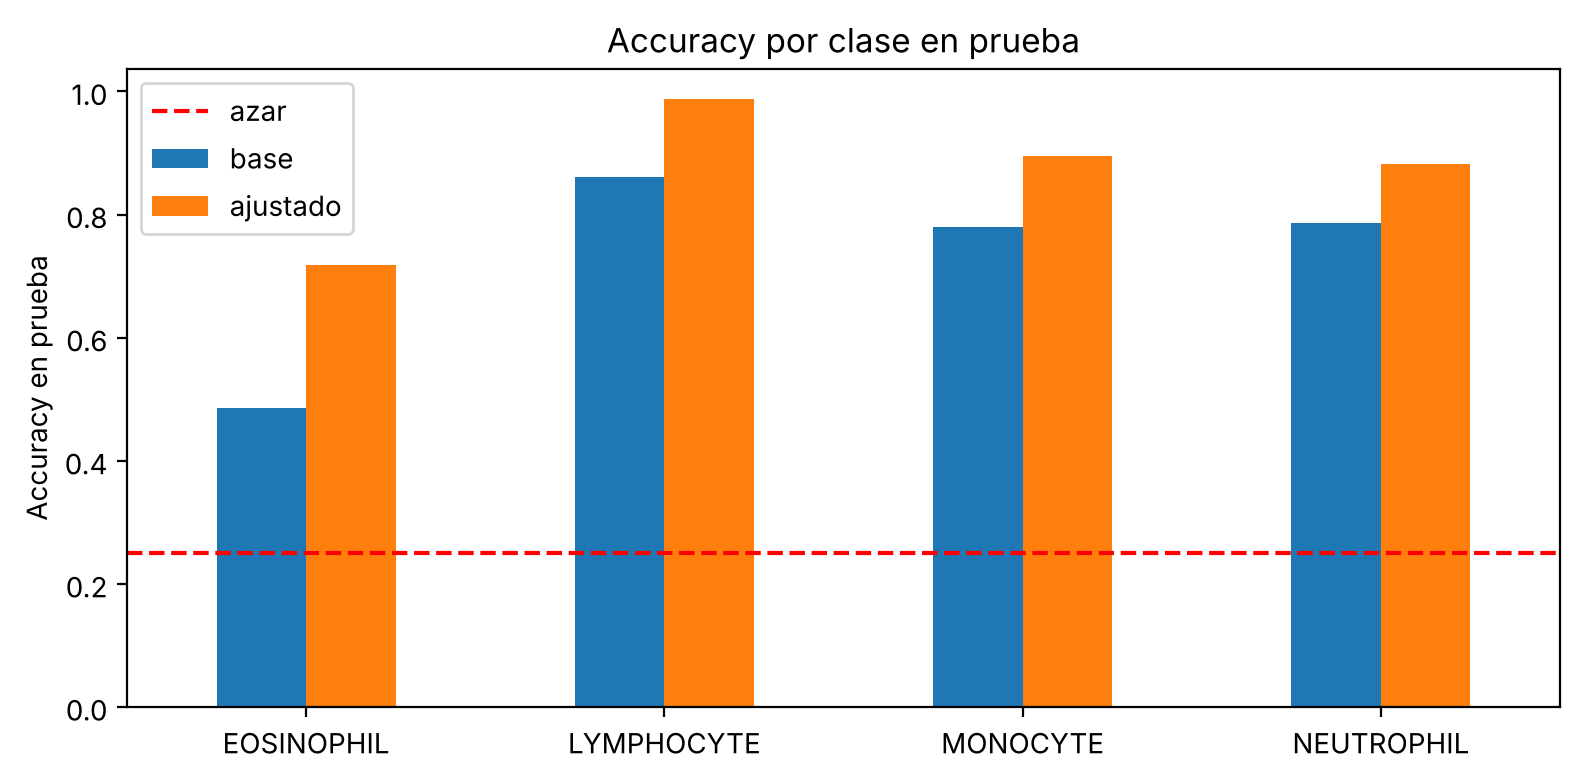

In [22]:
# accuracy por clase en prueba: modelo base contra modelo final
por_clase_prueba[["base", "ajustado"]].plot.bar(rot=0)
plt.axhline(0.25, color="red", linestyle="--", label="azar")
plt.ylabel("Accuracy en prueba")
plt.title("Accuracy por clase en prueba")
plt.legend()
plt.tight_layout()
plt.show()

Las cuatro clases quedan muy por arriba de la linea de azar y las cuatro mejoran respecto al modelo base. La mejora mas grande es la del eosinofilo, que pasa de 48.64 a 71.75 por ciento, aunque sigue siendo la clase mas baja.

Conclusiones

1. Se entreno una red convolucional que clasifica imagenes de globulos blancos en 4 tipos. El modelo final tiene un accuracy de 87.01 por ciento en el conjunto de prueba, formado por celulas que no se usaron en el entrenamiento. Adivinar al azar daria 25 por ciento.

2. El modelo base, sin regularizacion, llego a 94.84 por ciento en entrenamiento pero solo a 72.82 por ciento en prueba. La diferencia de 22.0 puntos mostro que el problema no era falta de capacidad sino sobreajuste.

3. Los cambios que funcionaron fueron el aumento de datos y el dropout, junto con mas epocas de entrenamiento. Con ellos el accuracy de prueba subio 14.2 puntos, de 72.82 a 87.01 por ciento, y los errores bajaron de 676 a 323.

4. Funcionaron porque atacan directamente el sobreajuste. Con el aumento de datos el modelo ve en cada epoca una version distinta de cada imagen, y con el dropout no puede apoyarse en unas pocas caracteristicas, asi que le resulta mas dificil memorizar las imagenes de entrenamiento. La evidencia es que el accuracy de entrenamiento casi no cambio (94.84 contra 95.51 por ciento) y lo que cambio fue la diferencia entre entrenamiento y prueba, que bajo de 22.0 a 8.5 puntos.

5. El error que queda esta concentrado en un solo par de clases. La confusion entre eosinofilo y neutrofilo suma 237 de los 323 errores, y el modelo predice neutrofilo mas veces de las que deberia (789 contra 624).

6. El accuracy de validacion (95.23 por ciento) quedo 8.2 puntos arriba del de prueba. Esto se debe a que la validacion se saco al azar de TRAIN y comparte celulas con el entrenamiento, por lo que no es una buena medida de generalizacion en este dataset.

Areas de mejora

1. Separar la validacion por celula y no por imagen, para que mida lo mismo que la prueba y se pueda usar para elegir el modelo sin recurrir al conjunto de prueba.

2. Entrenar mas epocas. La mejor epoca del modelo final fue la ultima, asi que todavia no habia terminado de converger.

3. Probar el aumento de datos y el dropout por separado. En este trabajo se aplicaron juntos, por lo que no se puede decir cuanto de la mejora aporta cada uno.

4. Conseguir mas celulas distintas para la prueba. Las 2487 imagenes salen de 71 celulas originales, y en el caso del monocito de solo 4, asi que el resultado por clase depende de muy pocas celulas.

5. Trabajar el par eosinofilo-neutrofilo, por ejemplo con imagenes de mayor resolucion, ya que lo que distingue a estas dos clases son detalles pequenos del nucleo y de los granulos.